# cRealNVP with Detailed Balance: Learning a Particle-Particle Collision Kernel

In a binary collision two particles (masses `m1`, `m2`) enter with velocities `(v1, v2)` and leave with `(v1', v2')`.
Momentum conservation fixes the centre-of-mass velocity `G`, so the collision is described completely by the
**relative velocity** `g = v1 − v2 → g' = v1' − v2'`. We learn the collision kernel `q(g' | g)` with a conditional
normalizing flow (condition `g`, target `g'`).

In equilibrium (Maxwellians at temperature `kT`) the kernel must satisfy **detailed balance** (DB):

`B(|g|) · M_μ(g) · q(g' | g)  =  B(|g'|) · M_μ(g') · q(−g | −g')`

- `M_μ(g) ∝ exp(−μ|g|² / 2kT)`: Maxwellian of the relative velocity, `μ = m1 m2 / (m1 + m2)` (the `G` part cancels),
- `B(|g|) = |g| σ_T(|g|) ∝ |g|^a`: collision-rate factor (VHS: `a = 2 − 2ω`; hard spheres `a = 1`, Maxwell molecules `a = 0`),
- `−g`: time reversal.

`B · M_μ` is the distribution of **colliding** pairs; it plays the role of the flux-weighted wall Maxwellian in the
gas-surface case. `CollisionDBLoss` penalizes the squared log-difference of both sides on arbitrary pairs `(g, g')`.

> **Disclaimer:** The models in this notebook are illustrative examples, not optimized results. Architectures, hyperparameters and training settings were chosen to keep the runtime short, not to reach maximum accuracy. The reported accuracies are therefore not the best achievable with this approach; there is most likely considerable room for improvement, e.g. through tuning of the network size, learning rate (schedule), batch size, number of epochs, DB-weight schedule and number of DB points.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from scipy import stats

from neuraldist.generative_model.registry import build_model
import neuraldist.generative_model.realnvp.crealnvp_db  # Import registers "crealnvp_db"
from neuraldist.losses import CollisionDBLoss, DBWeightScheduler, LinearRampWeight
from neuraldist.losses import from_relative_frame, reduced_mass, to_relative_frame
from neuraldist.training import fit_model

tf.keras.utils.set_random_seed(0)
rng = np.random.default_rng(0)

I0000 00:00:1794762377.648048   18828 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794762377.701739   18828 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794762379.291262   18828 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 2. The reference kernel

As exact reference we use **Maxwell molecules** (`a = 0`, collision rate independent of `|g|`) with an *inelastic*
relaxation kernel for the relative velocity:

`g' = ρ g + √(1 − ρ²) · √(kT/μ) · ξ`,  `ξ ~ N(0, I)`

The relative translational energy is not conserved in a single collision; the difference is exchanged with internal
degrees of freedom that are in equilibrium themselves (a heat bath, like the wall in the gas-surface case).
`ρ` is the memory of the collision (`ρ = 1`: no collision, `ρ = 0`: complete thermalization).
The kernel is an Ornstein-Uhlenbeck step and therefore reversible with respect to `M_μ`, i.e. it satisfies DB for `a = 0`.

The particles have different masses (`m1 = 1`, `m2 = 3`), so `μ = 0.75` and each component of `g` has the equilibrium
variance `kT/μ`.

In [2]:
M1, M2, KT = 1.0, 3.0, 1.0
MU = reduced_mass(M1, M2)
VAR = KT / MU                      # equilibrium variance of each component of g
SIG = np.sqrt(VAR)
RHO = 0.6                          # collision memory
VAR_Q = (1 - RHO**2) * VAR         # conditional variance of the kernel

db_loss_true = CollisionDBLoss(reduced_mass=MU, kT=KT, rate_exponent=0.0)   # Maxwell molecules


def collide(g, rng):
    """Draw g' from the exact kernel."""
    return RHO * g + np.sqrt(VAR_Q) * rng.standard_normal(g.shape)


def exact_log_q(g_post, g_pre):
    """Exact log q(g' | g)."""
    return stats.multivariate_normal(np.zeros(3), VAR_Q * np.eye(3)).logpdf(g_post - RHO * g_pre)


def exact_db_sides(g_pre, g_post, loss=db_loss_true):
    """Left and right side of the DB equation (log form) of the exact kernel."""
    d = loss.make_db_data(g_pre, g_post)
    return (exact_log_q(g_post, g_pre) + d["log_M_i"],
            exact_log_q(d["v_r_bwd"].astype(float), d["v_i_bwd"].astype(float)) + d["log_M_r"])

### Sanity check of the exact kernel

- The DB residual must vanish for arbitrary pairs.
- Colliding pairs from equilibrium must leave with the same distribution.
- In the lab frame momentum is conserved exactly, the translational energy only on average.

In [3]:
# DB residual at arbitrary pairs
g_a, g_b = rng.normal(0, 1.5 * SIG, (5000, 3)), rng.normal(0, 1.5 * SIG, (5000, 3))
lhs, rhs = exact_db_sides(g_a, g_b)
print(f"max |DB residual| of the exact kernel: {np.abs(lhs - rhs).max():.1e}")

# equilibrium preservation
g_eq = rng.normal(0, SIG, (200_000, 3))
g_out = collide(g_eq, rng)
print(f"g' std per component: {np.round(g_out.std(0), 3)} (target {SIG:.3f}) | "
      f"KS(|g'|, |g|) = {stats.ks_2samp(np.linalg.norm(g_out, axis=1), np.linalg.norm(g_eq, axis=1)).statistic:.4f}")

# lab frame
v1, v2 = rng.normal(0, np.sqrt(KT / M1), (200_000, 3)), rng.normal(0, np.sqrt(KT / M2), (200_000, 3))
G, g = to_relative_frame(v1, v2, M1, M2)
v1p, v2p = from_relative_frame(G, collide(g, rng), M1, M2)
dp = np.abs(M1 * v1 + M2 * v2 - M1 * v1p - M2 * v2p).max()
e_kin = lambda a, b: 0.5 * M1 * np.sum(a**2, 1) + 0.5 * M2 * np.sum(b**2, 1)
de = e_kin(v1p, v2p) - e_kin(v1, v2)
print(f"max |momentum change| = {dp:.1e} | translational energy change: mean {de.mean():+.4f}, std {de.std():.3f}")

max |DB residual| of the exact kernel: 3.0e-06
g' std per component: [1.155 1.153 1.157] (target 1.155) | KS(|g'|, |g|) = 0.0031
max |momentum change| = 1.8e-15 | translational energy change: mean -0.0008, std 1.386


## 3. Data

- **"MD" data:** only a few collisions from the true kernel. The particles are drawn from lab-frame Maxwellians and
  transformed into the relative frame (for Maxwell molecules every pair collides with the same rate, so no
  re-weighting by `B` is needed).
- **DB points:** many *arbitrary* pairs `(g, g')` from `CollisionDBLoss.sample_db_points`. DB holds for every pair, so
  these points need neither the true kernel nor collision data, only `kT`, `μ` and the rate law.

The flow works directly on `g ∈ ℝ³`, so there are no abstract variables and all log-Jacobians are 0.

In [4]:
N_MD, N_DB, BATCH = 300, 4096, 256


def md_pairs(n, rng=rng):
    """Collisions from the true kernel, colliding pairs drawn from the lab-frame equilibrium."""
    v1, v2 = rng.normal(0, np.sqrt(KT / M1), (n, 3)), rng.normal(0, np.sqrt(KT / M2), (n, 3))
    _, g = to_relative_frame(v1, v2, M1, M2)
    return g, collide(g, rng)


def broad_pairs(n, rng=rng):
    """Collisions from the true kernel with a broader distribution of g (tests the tails)."""
    g = rng.normal(0, 1.5 * SIG, (n, 3))
    return g, collide(g, rng)


g_md, g_md_post = md_pairs(N_MD)
db_data = db_loss_true.sample_db_points(N_DB, spread=1.5, rng=1)
print(f"MD pairs: {N_MD} | DB points: {N_DB}")
print({k: v.shape for k, v in db_data.items()})

MD pairs: 300 | DB points: 4096
{'v_i': (4096, 3), 'v_r': (4096, 3), 'v_i_bwd': (4096, 3), 'v_r_bwd': (4096, 3), 'log_det_jacobian_fwd': (4096,), 'log_det_jacobian_bwd': (4096,), 'log_M_i': (4096,), 'log_M_r': (4096,)}


### Evaluation helper

Three numbers, all on **fresh** samples:
- `KL_md`: `KL(p ‖ q)` for `g` like the training data,
- `KL_broad`: the same for a broader distribution of `g`,
- `DB_rms`: RMS DB residual of the model on arbitrary pairs, measured with the **true** rate law `a = 0`.

In [5]:
def kl(model, pairs):
    g, gp = pairs
    logq = model.log_prob(gp.astype("float32"), g.astype("float32")).numpy()
    return float(np.mean(exact_log_q(gp, g) - logq))


def db_rms(model, loss=db_loss_true, rng=None):
    rng = np.random.default_rng(rng)
    g, gp = rng.normal(0, 1.5 * SIG, (5000, 3)), rng.normal(0, 1.5 * SIG, (5000, 3))
    lhs, rhs = loss.db_sides(model, g, gp)
    return float(np.sqrt(np.mean((lhs - rhs) ** 2)))


def evaluate(model):
    return {"KL_md": kl(model, md_pairs(5000)), "KL_broad": kl(model, broad_pairs(5000)), "DB_rms": db_rms(model, rng=2)}


def train(use_db, db_loss=None, epochs=60, weight=1.0, seed=0, md=(g_md, g_md_post)):
    tf.keras.utils.set_random_seed(seed)
    model = build_model("crealnvp_db", x_dim=3, cond_dim=3, n_coupling=6)
    common = dict(batch_size=BATCH, epochs=epochs, steps_per_epoch=N_DB // BATCH)   # same number of steps for all runs
    g, gp = md
    if not use_db:
        return model, fit_model(model, gp, g, **common)
    db_loss = db_loss or CollisionDBLoss(MU, KT, rate_exponent=0.0)
    db_loss.epoch_weighting = LinearRampWeight(0.0, weight, 20)
    pts = db_loss.sample_db_points(N_DB, spread=1.5, rng=1)
    history = fit_model(model, gp, g, db_data=pts, compile_kwargs={"db_loss": db_loss},
                        callbacks=[DBWeightScheduler()], **common)
    return model, history

## 4. Baseline: cRealNVP with NLL only

In [6]:
flow_nll, hist_nll = train(use_db=False)
print({k: round(v[-1], 3) for k, v in hist_nll.history.items() if k in ("loss", "nll_fwd")})

E0000 00:00:1794762380.459628   18828 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


{'loss': 1.459, 'nll_fwd': 1.459}


## 5. cRealNVP with NLL + collision DB loss

The DB weight is ramped from 0 to 1 over 20 epochs. `db_acc = mean(exp(−|diff|))` is a mean Metropolis-Hastings-type
acceptance probability (1 = DB satisfied).

{'db_acc': 0.766, 'db_loss': 0.151, 'db_weight': 1.0, 'loss': 3.899, 'nll_fwd': 3.748}


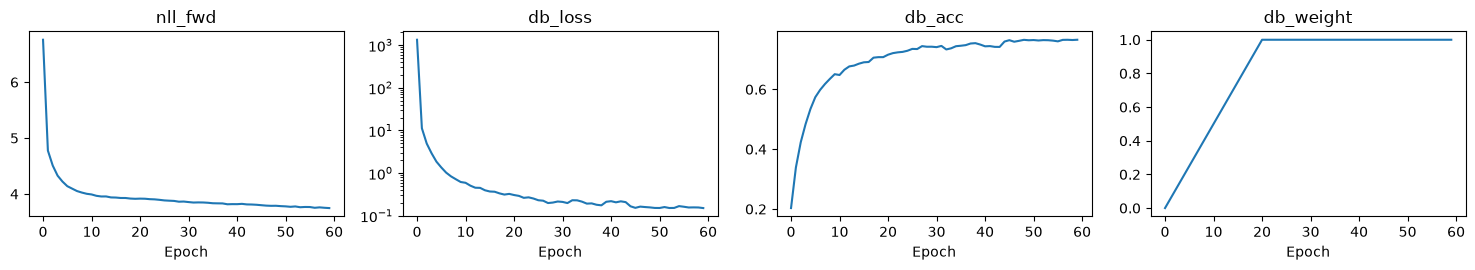

In [7]:
flow_db, hist_db = train(use_db=True)
print({k: round(v[-1], 3) for k, v in hist_db.history.items() if k in ("loss", "nll_fwd", "db_loss", "db_acc", "db_weight")})

fig, axes = plt.subplots(1, 4, figsize=(15, 2.8))
for ax, key in zip(axes, ["nll_fwd", "db_loss", "db_acc", "db_weight"]):
    ax.plot(hist_db.history[key])
    ax.set(title=key, xlabel="Epoch")
axes[1].set_yscale("log")
fig.tight_layout()
plt.show()

## 6. Comparison with the exact kernel

In [8]:
models = {"NLL only": flow_nll, "NLL + DB": flow_db}
scores = {name: evaluate(m) for name, m in models.items()}

print(f"{'model':10s} | {'KL_md':>9s} | {'KL_broad':>9s} | {'DB_rms':>9s}")
for name, s in scores.items():
    print(f"{name:10s} | {s['KL_md']:9.3f} | {s['KL_broad']:9.3f} | {s['DB_rms']:9.3f}")

model      |     KL_md |  KL_broad |    DB_rms
NLL only   |    52.378 |    85.640 |  1055.915
NLL + DB   |     0.061 |     0.106 |     0.854


**Observation:** With only 300 MD collisions the NLL-only flow overfits massively (KL ≈ 50–90, DB residual on arbitrary pairs around 1000). The flow with the collision DB loss reaches KL ≈ 0.06 (0.11 for the broad distribution) and a DB residual below 1, the same picture as in the gas-surface case. The baseline is deliberately unregularized (no early stopping, no weight decay): the point is that the DB term supplies information that the few collisions cannot. These values are not the limit of the method: neither the architecture nor the training (epochs, learning rate, DB-weight schedule, number of DB points) was tuned, so the accuracy of the DB-regularized flow can very likely be increased further.

### Detailed balance, left side vs. right side

`log q(g' | g) + log W(g)` (x-axis) against `log q(−g | −g') + log W(g')` (y-axis) with `W = B · M_μ`, on arbitrary
pairs and on pairs from the true kernel. A kernel in detailed balance lies on the diagonal.

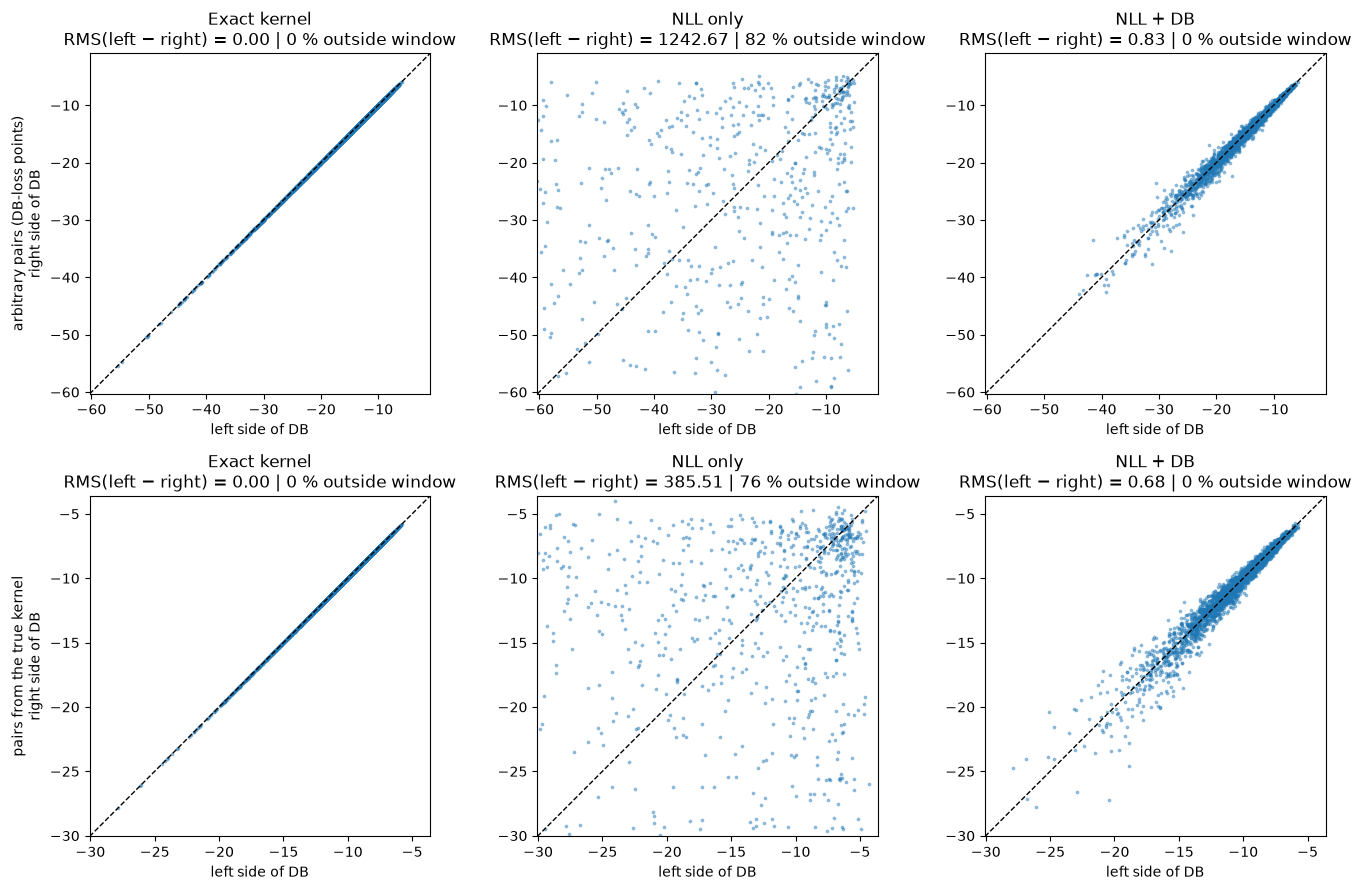

In [9]:
g_plot = np.random.default_rng(123)         # separate generator
n_plot = 3000
ga = g_plot.normal(0, 1.5 * SIG, (n_plot, 3))
pair_sets = {"arbitrary pairs (DB-loss points)": (ga, g_plot.normal(0, 1.5 * SIG, (n_plot, 3))),
             "pairs from the true kernel": (ga, collide(ga, g_plot))}

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for row, (set_name, (g, gp)) in enumerate(pair_sets.items()):
    sides = {"Exact kernel": exact_db_sides(g, gp)}
    sides.update({name: db_loss_true.db_sides(m, g, gp) for name, m in models.items()})
    exact = np.concatenate(sides["Exact kernel"])
    lo, hi = exact.min(), exact.max()
    lo, hi = lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo)
    for ax, (name, (lhs, rhs)) in zip(axes[row], sides.items()):
        inside = (lhs > lo) & (lhs < hi) & (rhs > lo) & (rhs < hi)
        rms = np.sqrt(np.mean((lhs - rhs) ** 2))
        ax.scatter(lhs[inside], rhs[inside], s=3, alpha=0.4)
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        ax.set(xlim=(lo, hi), ylim=(lo, hi), aspect="equal", xlabel="left side of DB",
               title=f"{name}\nRMS(left − right) = {rms:.2f} | {100 * (1 - inside.mean()):.0f} % outside window")
    axes[row, 0].set_ylabel(f"{set_name}\nright side of DB")
fig.tight_layout()
plt.show()

**Observation:** The exact kernel lies on the diagonal (RMS 0). For the NLL-only flow about 80 % of the points fall outside the plotting window and the residual is in the hundreds to thousands. The DB-regularized flow scatters closely around the diagonal; the scatter grows for very negative values, i.e. for unlikely pairs in the tails.

### Conditional density for one pre-collision velocity

For a fast collision `g = (2σ, 0, 0)` (σ = √(kT/μ)) the exact `g'` is Gaussian with mean `ρ g` and standard deviation
`√(1 − ρ²) σ` in every component. Histograms of model samples per component:

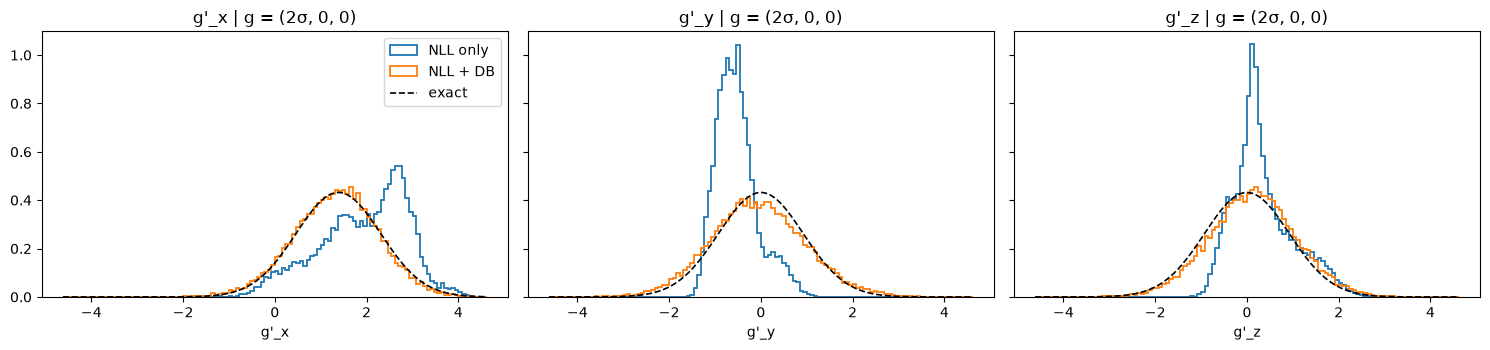

In [10]:
g_cond = np.array([[2 * SIG, 0.0, 0.0]], dtype="float32")
n_s = 20_000
x = np.linspace(-4 * SIG, 4 * SIG, 300)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for name, m in models.items():
    s = m.sample(n_s, cond=g_cond).numpy()[0]
    for k, ax in enumerate(axes):
        ax.hist(s[:, k], bins=120, range=(x[0], x[-1]), density=True, histtype="step", lw=1.3, label=name)
for k, ax in enumerate(axes):
    ax.plot(x, stats.norm.pdf(x, RHO * g_cond[0, k], np.sqrt(VAR_Q)), "k--", lw=1.2, label="exact")
    ax.set(title=f"g'_{'xyz'[k]} | g = (2σ, 0, 0)", xlabel=f"g'_{'xyz'[k]}")
axes[0].legend()
fig.tight_layout()
plt.show()

### Mean and spread as a function of the collision speed

Conditional mean of `g'_x` (exact: `ρ g_x`) and standard deviation of `g'_y` (exact: `√(1 − ρ²) σ`) for
`g = (g_x, 0, 0)`. The grey band marks typical training speeds; larger `|g|` are rare in the equilibrium data.

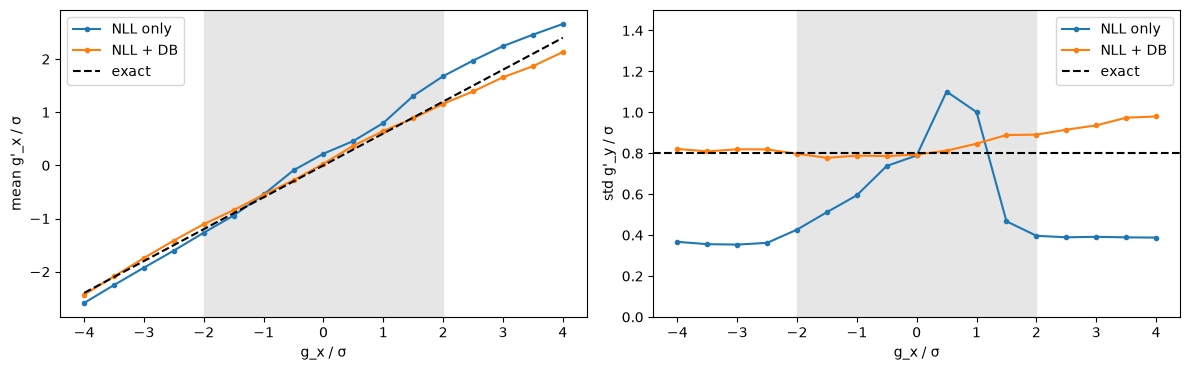

In [11]:
gx = np.linspace(-4 * SIG, 4 * SIG, 17)
conds = np.stack([gx, np.zeros_like(gx), np.zeros_like(gx)], 1).astype("float32")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, m in models.items():
    s = m.sample(4000, cond=conds).numpy()               # (17, 4000, 3)
    axes[0].plot(gx / SIG, s[..., 0].mean(1) / SIG, "o-", ms=3, label=name)
    axes[1].plot(gx / SIG, s[..., 1].std(1) / SIG, "o-", ms=3, label=name)
axes[0].plot(gx / SIG, RHO * gx / SIG, "k--", label="exact")
axes[1].axhline(np.sqrt(1 - RHO**2), color="k", ls="--", label="exact")
axes[0].set(xlabel="g_x / σ", ylabel="mean g'_x / σ")
axes[1].set(xlabel="g_x / σ", ylabel="std g'_y / σ", ylim=(0, 1.5))
for ax in axes:
    ax.axvspan(-2, 2, color="0.9", zorder=0)
    ax.legend()
fig.tight_layout()
plt.show()

**Observation:** The NLL-only flow memorizes the training collisions: its conditional density is multimodal and far too narrow (outside the grey band of typical training speeds its spread is about half of the exact value). The DB-regularized flow reproduces the Gaussian, the linear mean `ρ g` and the constant spread inside the training range. For `|g| > 2σ` it extrapolates reasonably, with a spread that grows by up to ~20 % at `|g| = 4σ`. The extrapolation error at large `|g|` can likely be reduced by tuning, e.g. with more DB points at high speeds or longer training.

## 7. Physical check in the lab frame

Particles of both species from their equilibrium Maxwellians collide with the learned kernel; the post-collision
velocities follow from `G` (unchanged) and the sampled `g'`. Momentum is conserved by construction. In equilibrium the
post-collision temperatures `m ⟨v²⟩ / 3` of both species must stay at `kT = 1`.

In [12]:
n = 50_000
gen = np.random.default_rng(7)
v1 = gen.normal(0, np.sqrt(KT / M1), (n, 3))
v2 = gen.normal(0, np.sqrt(KT / M2), (n, 3))
G, g = to_relative_frame(v1, v2, M1, M2)

samplers = {"exact": lambda g: collide(g, gen)}
samplers.update({name: (lambda g, m=m: m.sample(1, cond=g.astype("float32")).numpy()[:, 0]) for name, m in models.items()})

print(f"{'kernel':10s} | {'T1 after':>8s} | {'T2 after':>8s} | {'max |Δp|':>9s} | {'KS(|g\'|)':>8s}")
for name, sample in samplers.items():
    gp = sample(g)
    v1p, v2p = from_relative_frame(G, gp, M1, M2)
    T1, T2 = M1 * np.mean(v1p**2), M2 * np.mean(v2p**2)
    dp = np.abs(M1 * v1 + M2 * v2 - M1 * v1p - M2 * v2p).max()
    ks = stats.ks_2samp(np.linalg.norm(gp, axis=1), np.linalg.norm(g, axis=1)).statistic
    print(f"{name:10s} | {T1:8.3f} | {T2:8.3f} | {dp:9.1e} | {ks:8.4f}")

kernel     | T1 after | T2 after |  max |Δp| | KS(|g'|)
exact      |    1.000 |    1.000 |   8.9e-16 |   0.0045
NLL only   |    0.975 |    0.990 |   1.8e-15 |   0.0476


NLL + DB   |    1.013 |    1.001 |   8.9e-16 |   0.0095


**Observation:** Momentum is conserved to machine precision for every kernel, because `G` is never touched by the model. Both learned kernels keep the species temperatures close to `kT = 1` (deviations of 1–2.5 %), since the training collisions come from equilibrium. The post-collision speed distribution `|g'|` of the DB model is about five times closer to equilibrium (KS 0.01 vs. 0.05).

## 8. The rate law matters

The DB equation contains the collision-rate factor `B(|g|) ∝ |g|^a`. If the DB loss assumes the wrong rate law
(here hard spheres, `a = 1`, while the data come from Maxwell molecules), even the exact kernel violates the assumed
DB equation, and the DB loss pulls the flow towards a kernel whose colliding pairs are in equilibrium with
`|g| · M_μ(g)` instead of `M_μ(g)`.

In [13]:
db_loss_hs = CollisionDBLoss(MU, KT, rate_exponent=1.0)
lhs, rhs = exact_db_sides(g_a, g_b, loss=db_loss_hs)
print(f"exact kernel, DB residual with the wrong rate law a = 1: RMS = {np.sqrt(np.mean((lhs - rhs) ** 2)):.3f}")

flow_hs, hist_hs = train(use_db=True, db_loss=CollisionDBLoss(MU, KT, rate_exponent=1.0))
models_all = {**models, "NLL + DB (a=1, wrong)": flow_hs}
print(f"\n{'model':22s} | {'KL_md':>8s} | {'KL_broad':>8s} | {'DB_rms (a=0)':>12s} | {'DB_rms (a=1)':>12s}")
for name, m in models_all.items():
    s = scores.get(name) or evaluate(m)
    print(f"{name:22s} | {s['KL_md']:8.3f} | {s['KL_broad']:8.3f} | {s['DB_rms']:12.3f} | {db_rms(m, db_loss_hs, rng=2):12.3f}")

exact kernel, DB residual with the wrong rate law a = 1: RMS = 0.671



model                  |    KL_md | KL_broad | DB_rms (a=0) | DB_rms (a=1)
NLL only               |   52.378 |   85.640 |     1055.915 |     1056.082
NLL + DB               |    0.061 |    0.106 |        0.854 |        1.112


NLL + DB (a=1, wrong)  |    0.086 |    0.127 |        1.102 |        0.915


**Observation:** With the wrong rate law the exact kernel has a DB residual of ≈ 0.67, so the loss and the MD data contradict each other. The flow trained with `a = 1` is measurably worse (KL 0.086 vs. 0.061, broad 0.127 vs. 0.106), and each DB model satisfies best the rate law it was trained with. The degradation is moderate here, because the MD data anchor the kernel and much of the DB information (time reversibility, consistency between `g` and `g'`) does not depend on `B`. Still, the rate law must match the interaction model (VHS exponent `ω`) that generated the data. Single run per setting; the numbers vary between seeds.

## 9. Summary

- `CollisionDBLoss` transfers the detailed-balance regularization from gas-surface scattering to binary collisions:
  the relative velocity takes the role of the particle velocity, and the distribution of colliding pairs
  `B(|g|) · M_μ(g)` the role of the flux-weighted wall Maxwellian.
- The DB points are arbitrary pairs; they need `kT`, `μ` and the rate law, but no collision data.
- The rate law is part of the physics that enters the loss: with the wrong exponent the DB loss biases the kernel.
- All models are untuned examples: the reported accuracies are not the best achievable, and the accuracy can most likely be increased further by hyperparameter tuning and longer training.